<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/notebooks/practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd

# The direct raw link to the file on GitHub
url = 'https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/refs/heads/main/data/cleaned_fuel_grocery_data.csv'

# Load it directly into a pandas DataFrame
df = pd.read_csv(url)
df.head()

,Month,Diesel,Food and non-alcoholic beverages,Petrol,Month_DT,Month_Diff
0,2016 January,65.0,90.7,72.8,2016-01-01,NaN
1,2016 February,61.1,90.0,70.5,2016-02-01,31 days
2,2016 March,61.9,90.3,70.0,2016-03-01,29 days
3,2016 April,64.2,90.0,73.1,2016-04-01,31 days
4,2016 May,65.3,90.0,74.7,2016-05-01,30 days


Dataset Summary:


,Diesel,Food and non-alcoholic beverages,Petrol,Month_DT
count,129.000000,129.000000,129.000000,129
mean,87.556589,92.140310,91.182946,2021-05-01 16:55:48.837209344
min,61.100000,82.800000,70.000000,2016-01-01 00:00:00
25%,73.500000,85.500000,79.800000,2018-09-01 00:00:00
50%,81.600000,88.100000,87.000000,2021-05-01 00:00:00
75%,100.100000,100.000000,102.100000,2024-01-01 00:00:00
max,126.200000,106.600000,125.500000,2026-09-01 00:00:00
std,16.032807,8.138302,12.577088,NaN


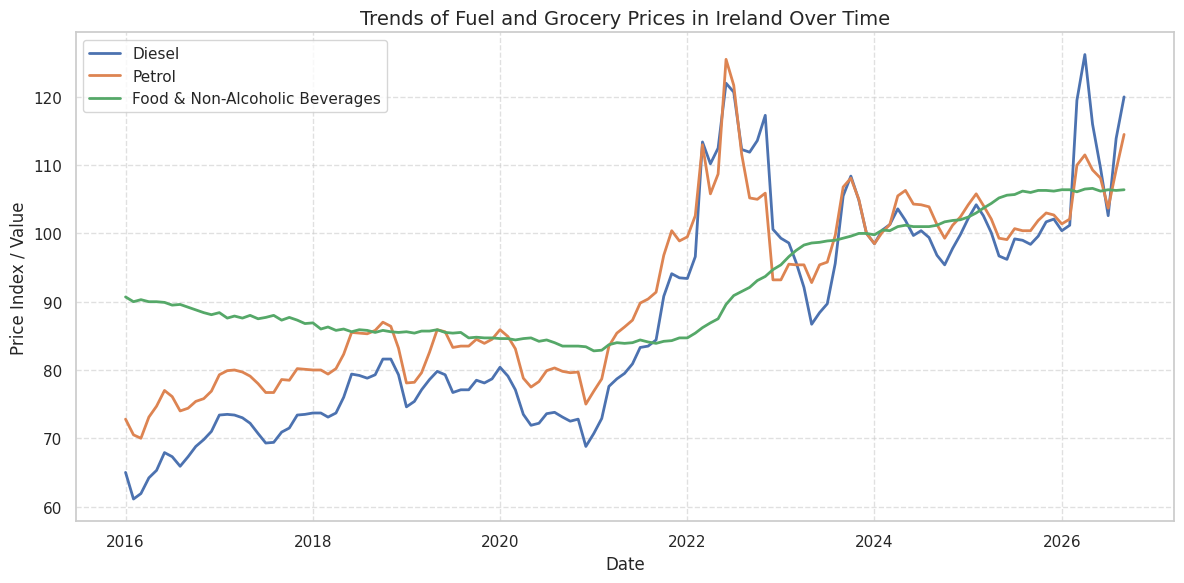

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure Month_DT is in datetime format for plotting
df['Month_DT'] = pd.to_datetime(df['Month_DT'])

# Quick overview of the dataset trends and statistics
print("Dataset Summary:")
display(df.describe())

# Plot the trends of Diesel, Petrol, and Food over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='Month_DT', y='Diesel', label='Diesel', linewidth=2)
sns.lineplot(data=df, x='Month_DT', y='Petrol', label='Petrol', linewidth=2)
sns.lineplot(data=df, x='Month_DT', y='Food and non-alcoholic beverages', label='Food & Non-Alcoholic Beverages', linewidth=2)

plt.title('Trends of Fuel and Grocery Prices in Ireland Over Time', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price Index / Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

--- Pearson Correlation Coefficient (Linear Relationship) ---


,Diesel,Petrol,Food and non-alcoholic beverages
Diesel,1.000000,0.979720,0.687407
Petrol,0.979720,1.000000,0.675527
Food and non-alcoholic beverages,0.687407,0.675527,1.000000



--- Spearman Rank Correlation Coefficient (Monotonic Relationship) ---


,Diesel,Petrol,Food and non-alcoholic beverages
Diesel,1.000000,0.983655,0.575555
Petrol,0.983655,1.000000,0.561315
Food and non-alcoholic beverages,0.575555,0.561315,1.000000



--- Trend Rates (Change per Day) ---
Diesel: Increases by approximately 4.3979 units per year (R² = 0.73)
Petrol: Increases by approximately 3.4607 units per year (R² = 0.73)
Food and non-alcoholic beverages: Increases by approximately 2.0629 units per year (R² = 0.62)


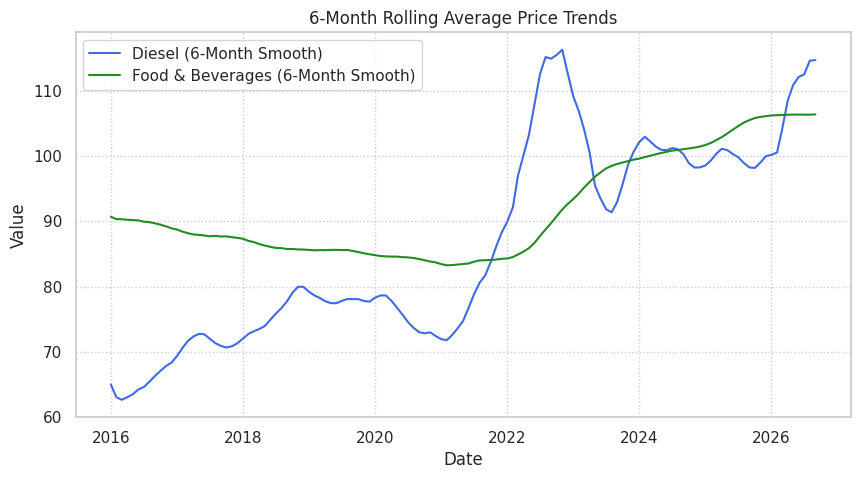

In [6]:
import numpy as np
import statsmodels.api as sm

# 1. Correlation Analysis (Quantifying relationships)
correlation_matrix = df[['Diesel', 'Petrol', 'Food and non-alcoholic beverages']].corr(method='pearson')
spearman_matrix = df[['Diesel', 'Petrol', 'Food and non-alcoholic beverages']].corr(method='spearman')

print("--- Pearson Correlation Coefficient (Linear Relationship) ---")
display(correlation_matrix)
print("\n--- Spearman Rank Correlation Coefficient (Monotonic Relationship) ---")
display(spearman_matrix)

# 2. Linear Regression (Quantifying the trend rate over time)
# Convert datetime to ordinal for numerical representation
df['Time_Ordinal'] = df['Month_DT'].apply(lambda x: x.toordinal())
X = sm.add_constant(df['Time_Ordinal'])

print("\n--- Trend Rates (Change per Day) ---")
for column in ['Diesel', 'Petrol', 'Food and non-alcoholic beverages']:
    model = sm.OLS(df[column], X).fit()
    slope = model.params['Time_Ordinal']
    r2 = model.rsquared
    print(f"{column}: Increases by approximately {slope*365.25:.4f} units per year (R² = {r2:.2f})")

# 3. Rolling Mean Analysis (Smoothing short-term volatility)
df['Diesel_6M_Rolling'] = df['Diesel'].rolling(window=6, min_periods=1).mean()
df['Food_6M_Rolling'] = df['Food and non-alcoholic beverages'].rolling(window=6, min_periods=1).mean()

# Quick plot of smoothed trends
plt.figure(figsize=(10, 5))
plt.plot(df['Month_DT'], df['Diesel_6M_Rolling'], label='Diesel (6-Month Smooth)', color='royalblue')
plt.plot(df['Month_DT'], df['Food_6M_Rolling'], label='Food & Beverages (6-Month Smooth)', color='forestgreen')
plt.title('6-Month Rolling Average Price Trends')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.grid(True, linestyle=':')
plt.show()